![logo](https://github.com/HelmholtzAI-Consultants-Munich/XAI-Tutorials/blob/main/docs/source/_figures/Helmholtz-AI.png?raw=true)

# Model-Agnostic Interpretation with LIME

In this notebook, we will demonstrate how to use the Local Interpretable Model-Agnostic Explanations (LIME) method ([Ribeiro et al., 2016](https://doi.org/10.1145/2939672.2939778)) and interpret its results.

--------

## Getting Started

### Setup Colab environment

If you installed the packages and requirements on your machine, you can skip this section and start from the import section.
Otherwise, you can follow and execute the tutorial on your browser. To start working on the notebook, click on the following button. This will open this page in the Colab environment, and you will be able to execute the code on your own.

<a href="https://colab.research.google.com/github/HelmholtzAI-Consultants-Munich/XAI-Tutorials/blob/main/xai-for-random-forest/Gen-2-Tutorial_LIME.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Now that you opened the notebook in Colab, run the next cell. It fetches the tutorials and installs the requirements. Running the notebook locally, that cell does nothing: you already have the repository and the requirements.

**Note:** Google Colab may ask you to restart the runtime after installing the required packages. If prompted, restart the runtime before continuing with the notebook.

In [1]:
# On Google Colab: fetch the course and install the requirements.
# Running locally this cell does nothing, because you already have the repository and installed the requirements yourself.
try:
    import google.colab  
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    %cd /content
    !rm -rf XAI-Tutorials
    !git clone --depth 1 --branch main https://github.com/HelmholtzAI-Consultants-Munich/XAI-Tutorials.git
    %cd XAI-Tutorials
    !pip install -r requirements_xai-for-random-forest.txt
    %cd xai-for-random-forest

### Imports

Let's start with importing all required Python packages.

In [2]:
import sys
import pickle

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from lime.lime_tabular import LimeTabularExplainer
from sklearn.linear_model import LinearRegression, Ridge # used as surrogate model for LIME

import warnings
warnings.filterwarnings('ignore')

# Make the local plotting helpers available.
sys.path.append("./")
import utils

# assert reproducible random number generation
seed = 1
np.random.seed(seed)

--------

## Introduction to Local Interpretable Model-Agnostic Explanations (LIME)

**We prepared a small [Introduction to LIME](https://xai-tutorials.readthedocs.io/en/latest/_model_agnostic_xai/lime.html) for you, to help you understand how this method works.**

*Note: we provide all references [here](https://xai-tutorials.readthedocs.io/en/latest/_model_agnostic_xai/lime.html#references).*

<font color='green'>

#### Questionnaire:

1. What is a surrogate model?

   A) A model trained to reproduce the labels in the original training data.  
   B) An interpretable model that approximates the predictions of a more complex model.  
   C) A more complex model used to verify the predictions of an interpretable model.  
   D) A model that measures how much each feature contributes to overall model performance.  

2. How does LIME use a surrogate model to explain a prediction?

   A) It removes each feature in turn, measures the change in model performance, and ranks the features.  
   B) It retrains the complex model using only data points near the sample being explained.  
   C) It samples data points near the sample being explained, obtains predictions from the complex model, and fits an interpretable model to approximate those predictions.  
   D) It fits an interpretable model to the entire training dataset and uses it to replace the complex model.  

3. What is a main difference between LIME and Permutation Feature Importance (PFI)?

   A) LIME explains one prediction at a time, while PFI measures how shuffling a feature affects model performance across a dataset.  
   B) LIME measures overall model performance, while PFI explains one prediction at a time.  
   C) Both methods explain one prediction at a time, but use different types of models.  
   D) LIME and PFI both require retraining the complex model for each feature.  

</font>

<div style="color: grey; font-size: 0.85em;">

#### Your Answer:

1. What is a surrogate model?

   ⚪ A) A model trained to predict the original target labels learns the task directly; a surrogate instead approximates another model’s predictions.  
   🟢 B) A surrogate is an interpretable model fitted to imitate a more complex model, making that model’s behavior easier to examine.  
   ⚪ C) A surrogate is generally simpler than the model it approximates; it is not a more complex model used to verify it.  
   ⚪ D) Feature importance measures how features affect predictions or performance. A surrogate instead approximates the predictions of another model.  

2. How does LIME use a surrogate model to explain a prediction?

   ⚪ A) Measuring performance changes after removing features is a different way to assess feature importance; LIME focuses on the model’s behavior near one instance.  
   ⚪ B) LIME does not retrain the complex model. It asks that model for predictions on perturbed samples near the instance being explained.  
   🟢 C) LIME uses the complex model’s predictions for nearby perturbed samples to fit a simpler model. That local model helps explain the prediction for the selected instance.  
   ⚪ D) LIME fits its surrogate around the selected instance, rather than fitting a global model on the entire dataset to replace the complex model.  

3. What is a main difference between LIME and Permutation Feature Importance (PFI)?

   🟢 A) LIME examines model behavior around one selected instance. PFI measures how model performance changes when a feature is shuffled across a dataset.  
   ⚪ B) This describes the methods in reverse: LIME explains an individual prediction, while PFI typically summarizes performance changes across a dataset.  
   ⚪ C) LIME explains one prediction at a time, whereas PFI assesses the effect of shuffling a feature across multiple samples.  
   ⚪ D) Neither method requires retraining the complex model for each feature. LIME queries it on nearby samples, while PFI evaluates it with a feature shuffled.  

</div>

--------

## Data and Model Loading: The California Housing Dataset

In this notebook, we will work with the **California Housing dataset**, containing 20,640 median house values for California districts (expressed in $100,000), which are described by 8 numeric features. Each row in the dataset represents a block of houses, not a single household. The data pertains to the house prices found in a given California district and some summary statistics about them based on the 1990 census data. Our goal is to **predict the price** of house blocks and find the most predictive features.

<center><img src="https://github.com/HelmholtzAI-Consultants-Munich/XAI-Tutorials/blob/main/docs/source/_figures/dataset_california_housing.jpg?raw=true" width="900" /></center>

<font size=1> Source: [Link](https://www.kaggle.com/datasets/harrywang/housing)

In the notebook [*Gen-0-Tutorial_RandomForest_Model_Housing_Wine_Penguins.ipynb*](./Gen-0-Tutorial_RandomForest_Model_Housing_Wine_Penguins.ipynb), we explain how to do the exploratory data analysis, preprocess the data and train a Random Forest model with the given data. The focus of this notebook is the interpretation of the previously trained model.

In [3]:
# Load the saved data splits and the already trained Random Forest
with open("../models/model_rf_housing.pickle", "rb") as handle:
    X_train, X_test, y_train, y_test, model_housing, _ = pickle.load(handle)

print(f"Model Performance on training data: {model_housing.score(X_train, y_train):.2f} R^2.")
print(f"Model Performance on test data: {model_housing.score(X_test, y_test):.2f} R^2.")

Model Performance on training data: 0.84 R^2.
Model Performance on test data: 0.72 R^2.


As we can see by the numbers above, our model performs well on the training set and also generalizes well to the independent test set.

**You should keep in mind that interpreting a low-performing model can lead to wrong conclusions.**

*Note: The $R^2$ is the coefficient of determination, and the closer this value is to 1, the better our model explains the data. A constant model that always predicts the average target value disregarding the input features would get an $R^2$ score of 0. However, the $R^2$ score can also be negative because the model can be arbitrarily worse.*

## Now, what does my model think is important in the data?

Now let's use LIME to get some insights into the Random Forest Regression model we loaded above. We first have to specify an important parameter for LIME: the *kernel_width*, which, in principle, determines how large the neighborhood around our sample will be. The optimal choice of this parameter is difficult and currently still an open research question and one of the main disadvantages of the method. Feel free to play around with different values and observe how the generated explanations can change.

*Note: this method is a local method, which means that it only provides explanations for individual samples but not for a full dataset.*

In [4]:
explainer = LimeTabularExplainer(
    training_data=X_train,          # LIME uses the training data to learn the feature distributions for generating perturbed samples. These values are standardized, as they were for model training.
    mode="regression",              # The model predicts a continuous target.
    training_labels=y_train,        # Target values for the training samples.
    feature_names=X_train.columns,  # Names used to identify features in the explanation.
    feature_selection="none",       # Use all features when fitting the local surrogate model.
    random_state=seed,              # Makes LIME's random sampling reproducible.
    sample_around_instance=True,    # Generate perturbed samples around the instance being explained.
    kernel_width=1,                 # Controls how close the generated samples should be to the instance being explained.
    discretize_continuous=False,    # Keep continuous features as numbers instead of grouping them into intervals.
)

Once we have defined the setup for LIME, we have to choose an instance of interest for which we want to get explanations, the neighborhood size, i.e., the number of points we want to sample in the neighborhood of our instance of interest to build the surrogate model, and the type of surrogate model. The size of the neighborhood should be chosen large enough because the surrogate model needs a sufficient number of data points for training. As a surrogate model, we choose the linear regression model because the coefficients of a linear model allow an intrinsic interpretation of the model.

*Note: when you are using a linear model as a surrogate model, you have to ensure that the input data is properly standardized beforehand. Our data was standardized before training the Random Forest model.*

In [5]:
# NOTE: LIME expects NumPy arrays, so convert the pandas DataFrames and Series.
X_train_array = X_train.to_numpy()
y_train_array = y_train.to_numpy()

In [6]:
# choose an instance that you want to explain
inst_idx = 0
print(f"Instance {inst_idx} of training data will be explained.")

Instance 0 of training data will be explained.


In [7]:
# Select the sample to explain and its observed target value.
instance = X_train_array[inst_idx]

explanation = explainer.explain_instance(
    data_row=instance,
    predict_fn=model_housing.predict,       # LIME calls this function to get predictions for the perturbed samples.
    model_regressor=LinearRegression(),     # Interpretable local surrogate model.
    num_samples=5000,                       # Number of perturbed samples used to fit the surrogate.
)

All that LIME did was to fit a linear regression model to approximate the complex model's predictions, i.e., the predictions of the Random Forest model. The dataset for creating the fit consists of the neighborhood samples that were randomly created around our selected instance. 

Linear regression models estimate a single parameter (coefficient) for each feature. Those coefficients describe the mathematical relationship between each feature (independent variable) and the target (dependent variable). The sign of a linear regression coefficient tells you whether there is a positive or negative correlation between the feature and the target. The coefficient value signifies how much the mean of the target changes given a one-unit shift in the feature while holding other features in the model constant. Hence, we can plot the coefficients of the Linear Regression Surrogate model to understand which features are most predictive for our instance of interest.

*Note: LIME is not restricted to linear regression models; other easy-to-interpret surrogate models could be used like decision trees.*

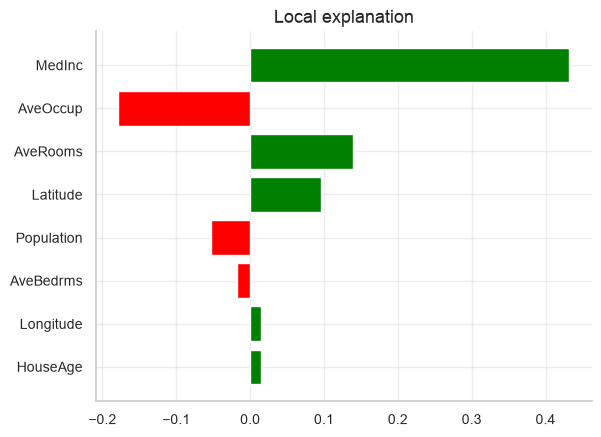

In [8]:
# Create and display a plot of the local explanation.
# The semicolon suppresses Jupyter's automatic display of the returned figure, preventing it from being displayed a second time.
explanation.as_pyplot_figure(); 

Two of the most informative features for the model are the *median income* (MedInc) and *average occupancy* (AveOccup), which are the features with the highest absolute model coefficients. The positive sign of the *median income* coefficient indicates a positive relation between this feature and the target variable (*price*), i.e., a higher income leads to higher price predictions. On the other hand, the negative sign of the *average occupancy* coefficient suggests that as the occupancy (i.e., more people living in the house block) increases, the price tends to decrease.  

To measure how well the simpler surrogate model is able to approximate the predictions of the more complex model, we can use any metric that summarizes the quality of the predictions that the surrogate model makes. This chosen metric can serve as a "fidelity measure", which indicates how reliable the interpretable model is. Even though the choice of the fidelity measure is up to you, it is important to assess the predictive ability of the surrogate model when LIME explanations are to be used!

How much would you trust explanations delivered from a surrogate model that cannot reasonably approximate the complex model's predictions?

In our case, we used a linear regression model as a surrogate model. A commonly used metric to quantify the goodness of fit for the linear regression model is the $R^2$ score. It shows how well the linear model is able to approximate the predictions of the more complex model on the neighborhood samples. $R^2$ scores closer to 1 indicate better approximations. Our surrogate model achieves an $R^2$ score of ~ 0.8, indicating that the explanations given by that model can be trusted.

In [9]:
# Show how well the local surrogate fits LIME's sampled predictions.
explanation.score

0.8103070578577939

<font color='green'>

#### Question: How should we interpret LIME explanations for two districts?

We use LIME to explain the predicted prices of two California housing districts. Both have high predicted prices, but their features differ. We use the same `kernel_width` and number of perturbed samples for both explanations. The local model has a high score for the first district and a low score for the second.

How should we interpret the feature importances for these two districts, and what role might `kernel_width` play in the second explanation?

</font>

<div style="color: grey; font-size: 0.85em;">

#### Your Answer:

LIME explains each district separately, so the feature importances describe how the model behaves near that district. For the first district, the high local model score indicates that LIME’s simpler model closely approximates the original model in the sampled neighborhood. The feature importances are therefore a useful summary of the local behavior.

For the second district, the low score indicates that the simpler model does not approximate the original model as well in the sampled neighborhood. Its feature importances may be less representative and should be interpreted cautiously. Changing `kernel_width` changes which perturbed samples count as neighbors, so it may improve the local model’s fit. However, a higher score would not make the explanation global: it would still describe the model near that one district.

</div>

--------

<font color='green'>

### Task: Apply LIME to the Wine Classifier

In this exercise, you will apply **LIME (Local Interpretable Model-Agnostic Explanations)** to the trained Random Forest classifier to understand how chemical properties influence individual wine classification predictions.

1. Define a `LimeTabularExplainer` for the classification model, using the training data and feature names.
2. Implement a function that generates and plots a LIME explanation for one sample.
3. Apply the function to each of the three samples.
4. Experiment with LIME parameters, such as the number of neighborhood samples (`num_samples`), the kernel width (`kernel_width`), or the surrogate model, and consider how they affect the explanations.
5. Interpret the plots: identify which features support or oppose each predicted class, and compare the explanations across samples.

> **Hint:** In the regression example, LIME explains a continuous prediction, so you passed the model’s `predict` method and did not need to specify a class. For classification, pass the model’s `predict_proba` method and choose which class to explain: use `labels=(class_id,)` to request a specific class, or `top_labels=1` to explain the class with the highest predicted probability. With `top_labels=1`, use `explanation.top_labels[0]` to get the class explained in the plot. This is the predicted class and may differ from the sample’s true label.

</font>

**The Wine dataset**

Let's use the wine quality dataset to see how XAI can be used to explain multiclass classification models. The **Wine Recognition dataset** contains 178 wine samples from three different cultivars of wine in the same region in Italy. The wine was chemically analyzed and 13 different chemical attributes like *alcohol*, *malic acid*, *flavanoids*, etc. were measured. Our goal is to **classify wines** and find the most predictive features.

<center><img src="https://github.com/HelmholtzAI-Consultants-Munich/XAI-Tutorials/blob/main/docs/source/_figures/dataset_red_wine.jpg?raw=true" width="900" /></center>

<font size=1> Source:
[Link](https://www.kaggle.com/datasets/uciml/red-wine-quality-cortez-et-al-2009)

In the notebook [*Gen-0-Tutorial_RandomForest_Model_Housing_Wine_Penguins.ipynb*](./Gen-0-Tutorial_RandomForest_Model_Housing_Wine_Penguins.ipynb), we explain how to do the exploratory data analysis, preprocess the data and train a Random Forest model with the given data. The focus of this notebook lies on the interpretation of the previously trained model.

In [10]:
# Replace the housing data with the wine data and its trained classifier.
with open("../models/model_rf_wine.pickle", "rb") as handle:
    X_train, X_test, y_train, y_test, model_wine, _ = pickle.load(handle)

# For this classifier, .score() returns accuracy rather than R².
print(f"Model Performance on training data: {model_wine.score(X_train, y_train) * 100:.2f}% accuracy.")
print(f"Model Performance on test data: {model_wine.score(X_test, y_test) * 100:.2f}% accuracy.")

X_train_array = X_train.to_numpy()
y_train_array = y_train.to_numpy()

Model Performance on training data: 100.00% accuracy.
Model Performance on test data: 97.22% accuracy.


As shown by the metrics above, the model achieves perfect performance on the training set while also generalizing very well to the independent test set.

**Understanding Local Feature Contributions in the Wine Dataset**

We can now apply LIME to better understand how the trained model uses the different chemical properties to make predictions for individual wine samples and distinguish between the three wine classes.


In [11]:
# Set the width of the local neighborhood around the sample being explained.
# The value is scaled to the number of features; smaller values give more weight to samples closer to the instance.
kernel_width = 0.75 * np.sqrt(13)

# TASK: Experiment with this parameters to see how the neighborhood width affects the LIME explanations.

In [12]:
# TASK: Create a LIME explainer configured for a classification problem.
# <add your code here>
explainer = LimeTabularExplainer(
    training_data=X_train,          # Standardized training features, used to generate perturbed samples.
    mode="classification",          # The model predicts classes rather than a continuous value.
    training_labels=y_train,        # Class labels for the training samples.
    feature_names=X_train.columns,  # Names to use for features in the explanation.
    feature_selection="none",       # Keep all features in the local surrogate model.
    random_state=seed,              # Make LIME's random sampling reproducible.
    sample_around_instance=True,    # Generate perturbed samples around the instance being explained.
    kernel_width=kernel_width,      # Controls how close the generated samples should be to the instance being explained.
    discretize_continuous=False,    # Keep continuous features numeric instead of grouping them into intervals.
)

In [13]:
# TASK: Implement the function explain_and_plot() that explains and plots the predicted class for one wine sample using LIME. 
# <add your code here>
def explain_and_plot(X_train_array, y_train_array, inst_idx, model_wine, num_samples):
    # Select the feature values and true class label for this training sample.
    instance = X_train_array[inst_idx]
    instance_label = y_train_array[inst_idx]

    # Ask LIME to explain the model's predicted class for this instance.
    # LIME queries predict_proba for probabilities on its perturbed samples,
    # then fits a local Ridge regression model to approximate those probabilities.
    explanation = explainer.explain_instance(
        data_row=instance,                                  # The sample whose prediction we want to explain.
        predict_fn=model_wine.predict_proba,                # Classification models must return class probabilities.
        top_labels=1,                                       # Explain the class with the highest predicted probability.
        model_regressor=Ridge(alpha=3, random_state=seed),  # Regularized linear model used as the local surrogate.
        num_samples=num_samples,                            # Number of perturbed samples used to fit the surrogate.
    )

    # Get the class LIME explained; this may differ from the sample's true class.
    explained_label = explanation.top_labels[0]

    # The score indicates how well the local surrogate approximates the model
    # around this sample; it is not the Random Forest's overall accuracy.
    print(
        f"Instance {inst_idx} with true class {instance_label} "
        f"is explained for predicted class {explained_label}. "
        f"The surrogate model score is {explanation.score:.2f}."
    )

    # Plot the feature contributions for the explained class.
    explanation.as_pyplot_figure(label=explained_label)

In [14]:
# Number of perturbed samples LIME will generate to fit its local model.
num_samples = 5000

# TASK: Experiment with this parameters to see how the number of perturbed samples affects the LIME explanations.

Instance 4 with true class type_1 is explained for predicted class 0. The surrogate model score is 0.54.


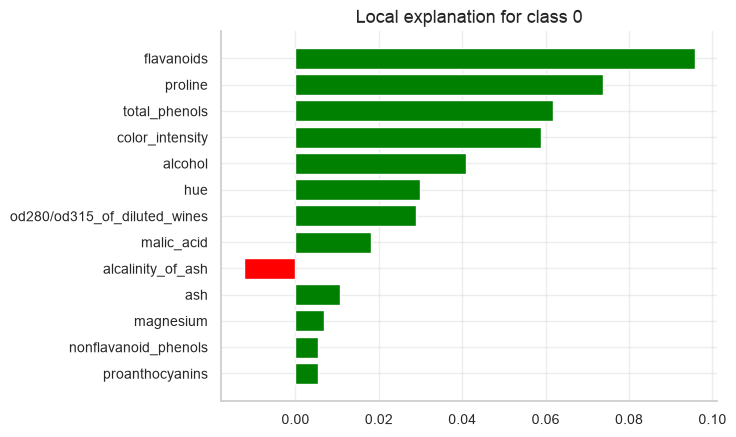

In [15]:
inst_idx = 4
explain_and_plot(X_train_array, y_train_array, inst_idx, model_wine, num_samples)

Instance 1 with true class type_2 is explained for predicted class 1. The surrogate model score is 0.67.


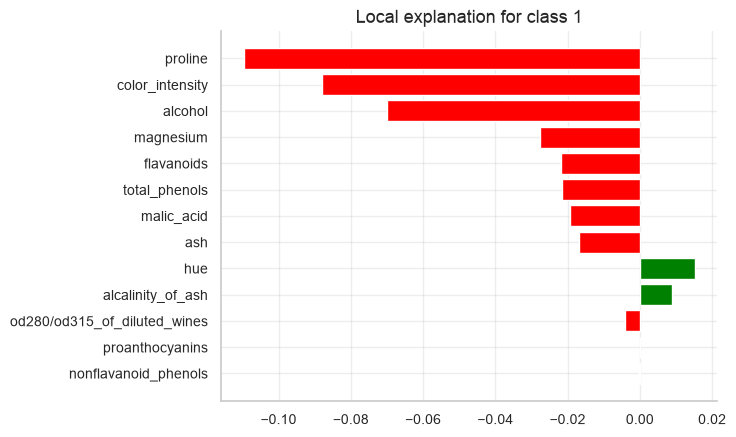

In [16]:
inst_idx = 1
explain_and_plot(X_train_array, y_train_array, inst_idx, model_wine, num_samples)

Instance 101 with true class type_3 is explained for predicted class 2. The surrogate model score is 0.76.


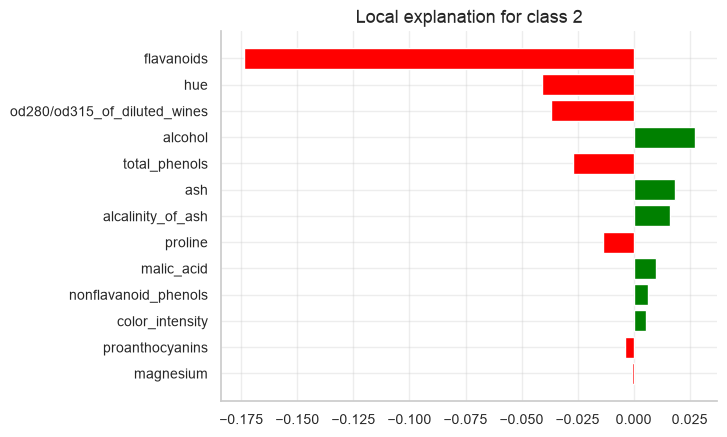

In [17]:
inst_idx = 101
explain_and_plot(X_train_array, y_train_array, inst_idx, model_wine, num_samples)

<font color='green'>

#### Conclusions

The LIME explanations provide local insights into how the Random Forest model distinguishes between the three wine classes based on the chemical properties of individual wine samples. Although the globally important features already highlighted the relevance of variables such as *flavanoids*, *proline*, *alcohol*, and *color intensity*, the local explanations reveal that the importance and direction of these features vary substantially between individual predictions.

For the sample belonging to **class type_1**, features such as *flavanoids*, *proline*, and *total phenols* strongly support the prediction, while *alcalinity_of_ash* slightly decreases the model confidence. In contrast, the explanation for **class type_2** shows that high values of *proline*, *color intensity*, and *alcohol* negatively contribute to this class prediction, whereas features such as *hue* provide positive evidence. For the **class type_3** sample, the model mainly relies on negative contributions from *flavanoids*, *hue*, and *od280/od315_of_diluted_wines*, while features such as *alcohol* and *alcalinity_of_ash* increase the prediction confidence.

The surrogate model scores indicate how well the local linear approximation captures the behavior of the underlying Random Forest model around the selected sample. While the explanation for class type_3 achieves a reasonably good surrogate score of approximately 0.75, the scores for class type_1 (0.55) and class type_2 (0.68) are comparatively low. This suggests that the local linear surrogate only approximates the true model behavior moderately well in these regions of the feature space. Consequently, the corresponding LIME explanations should be interpreted with caution.

</font>

--------

## Extra Material: LIME computation step by step

To get a better understanding of LIME, we will now guide you step by step through the algorithm. Even though LIME offers an easy-to-use API, it can be beneficial to have a quick look behind the scenes to fully understand what is going on. LIME is especially suitable here since the basic algorithm can be programmed in just a few steps.

[Cristian Arteaga](https://nbviewer.org/urls/arteagac.github.io/blog/lime.ipynb) has also prepared a nice step-by-step explanation of LIME for a 2D toy problem and we recommend taking a look at his notebook which contains nice visualizations.
Here, we are focusing on tabular data, but Cristian also provides a notebook that demonstrates how LIME can work on other modalities like images as well, which is one of its big strengths!

In [18]:
# Load the standardized data splits and the trained Random Forest model.
with open("../models/model_rf_housing.pickle", "rb") as handle:
    X_train, X_test, y_train, y_test, model_housing, _ = pickle.load(handle)

# Convert the training data to NumPy arrays for the neighborhood calculations.
X_train_array = X_train.to_numpy()
y_train_array = y_train.to_numpy()

### Step 1
First, we select an instance for which we want to explain the prediction.
We generate many normally distributed random samples that will serve as our sample neighborhood.
The samples' expected value coincides with our instance to ensure sufficient similarity between the neighborhood and our instance, while the standard deviation is estimated from the training data.

Also note that we make our instance itself part of the neighborhood.

In [19]:
# Select the training instance whose prediction we want to explain.
x = X_train_array[inst_idx]

# Use the training data's feature-wise standard deviations to generate
# realistic-sized perturbations around the selected instance.
std = X_train_array.std(axis=0)

# Center the neighborhood on the selected instance so that generated samples
# are likely to be close to it.
mu = x

# Generate perturbed samples around the selected instance.
num_samples = 5000
neighbors_of_x = np.random.normal(mu, std, size=(num_samples, X_train_array.shape[1]))

# Include the original instance in the neighborhood.
neighbors_of_x[0] = x

### Step 2
We let our original model predict the outcomes of the neighborhood samples.

In [20]:
# Get the Random Forest's predictions for the neighborhood.
# These predictions, rather than the observed target values, are what the simpler model will learn to approximate.
neighbors_of_x_pred = model_housing.predict(neighbors_of_x)

### Step 3
We compute the distance of each neighbor to our instance and transform it to a weight which we will later use to fit our local surrogate model.
Note that distances are computed on standardized data in order to avoid numerical instabilities.

In [21]:
# Calculate the squared Euclidean distance from each perturbed sample to x.
# The features are standardized, so distances are measured on a comparable scale.
kernel_width = 1
distance_to_x = np.sum((neighbors_of_x - x) ** 2, axis=1)

# Give closer samples more influence when fitting the local model.
weights = np.sqrt(np.exp(-1.0 * (distance_to_x / kernel_width) ** 2))

### Step 4
A surrogate model is fit to approximate the complex model's prediction on the neighborhood samples. We will use a linear regression model since that offers fairly straightforward explanations by looking at the estimated model coefficients. The fit will be performed again on the standardized samples!

The weights computed above will serve to indicate their importance to the fit. Samples with large weights are closer to our instance and should get predicted more accurately than neighbors further apart from our instance.

In [22]:
# Fit a linear model to approximate the Random Forest's predictions nearby.
# The sample weights emphasize the samples closest to x.
explainable_model = LinearRegression()
explainable_model.fit(
    neighbors_of_x,
    neighbors_of_x_pred,
    sample_weight=weights,
)

# This weighted R² score measures how well the linear model approximates the
# Random Forest's predictions for this sampled neighborhood.
score = explainable_model.score(
    neighbors_of_x,
    neighbors_of_x_pred,
    sample_weight=weights,
)
print("\nLocal model score:", score)


Local model score: 0.7795907233776833


### Step 5
We visualize the model coefficients to obtain a similar explanation as the LIME API offers us.

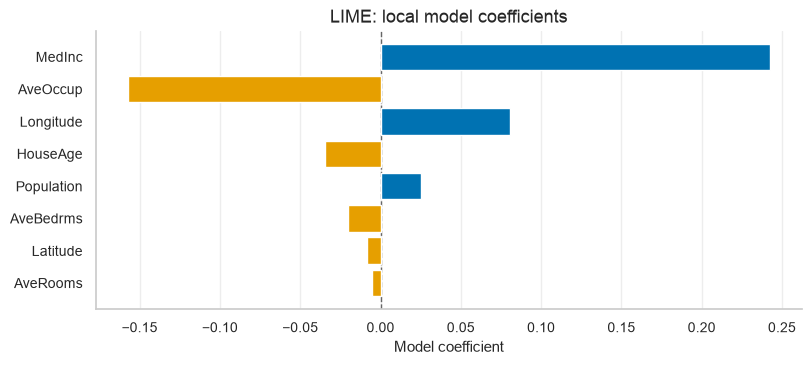

In [23]:
# Pair each feature name with its local model coefficient.
# Larger absolute coefficients indicate a stronger contribution in this
# linear approximation; the sign indicates the direction of that contribution.
coef_dict = dict(zip(X_train.columns, explainable_model.coef_))
coef_dict_sorted = dict(
    sorted(coef_dict.items(), key=lambda item: abs(item[1]), reverse=False)
)
coef_df = pd.DataFrame.from_dict(
    coef_dict_sorted,
    columns=["model coefficient"],
    orient="index",
)

# Plot the local coefficients to inspect how the linear model approximates
# the Random Forest's prediction around the selected instance.
utils.plot_lime_coefficients(coef_df=coef_df)